## Autorzy:
## Błażej Kazior 252758
## Hubert Gryl 250962

# Challenge: minimalna moc rozpraszana na mostku rezystorów

**Zadanie:** układ to mostek z pięciu rezystorów. R1 i R4 tworzą górną gałąź, R2 i R5 dolną, a R3 łączy węzeł górny z dolnym. Napięcia na wszystkich rezystorach są znane. Prąd każdego rezystora może różnić się od wartości podanej w tabeli najwyżej o $\Delta_i$:
$$I_i - \Delta_i \le I_i^{rzecz} \le I_i + \Delta_i, \qquad i = 1 \dots 5$$

Trzeba tak **dobrać rezystancje**, żeby całkowita moc rozpraszana na rezystorach była jak najmniejsza.

| Rezystor | R1 | R2 | R3 | R4 | R5 |
|---|---|---|---|---|---|
| Napięcie $U_i$ [V] | 6 | 10 | 4 | 7 | 3 |
| Prąd $I_i$ [mA] | 4 | 2 | 2 | 2 | 4 |
| Tolerancja $\Delta_i$ [mA] | 1 | 1 | 1 | 1 | 1 |
| Dopuszczalny prąd [mA] | 3 … 5 | 1 … 3 | 1 … 3 | 1 … 3 | 3 … 5 |


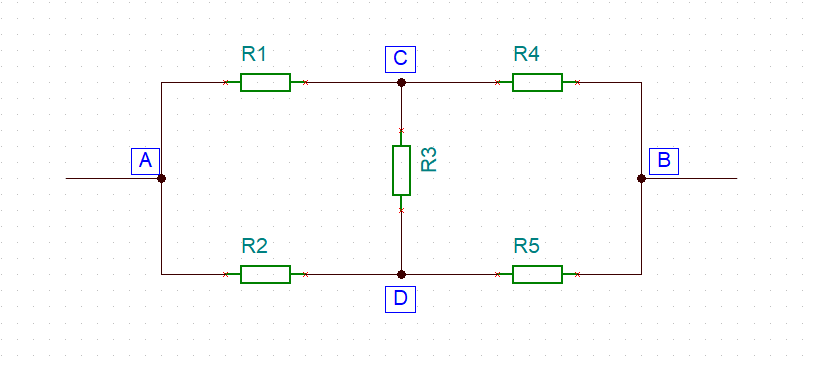

Rys. 1. Schemat mostka z treści zadania

Oznaczenia węzłów: A — wejście, C — węzeł górny (między R1 i R4), D — węzeł dolny (między R2 i R5), B — wyjście. Prąd w R3 płynie z C do D, tak jak na schemacie.

## 1. Jak zapisać to jako problem liniowy?

Zmiennymi są rezystancje, a moc na rezystorze przy znanym napięciu wynosi wtedy $P_i = \frac{U_i^2}{R_i}$, a to **nie jest funkcja liniowa** (rezystancja jest w mianowniku).

Napięcia są stałe, więc rezystancję i prąd łączy prawo Ohma $R_i = U_i / I_i$. Każdemu prądowi odpowiada dokładnie jedna rezystancja. Jeśli za zmienne weźmiemy **prądy**, moc jest już liniowa:
$$P = \sum_i U_i I_i = 6 I_1 + 10 I_2 + 4 I_3 + 7 I_4 + 3 I_5 \quad [\text{V} \cdot \text{mA} = \text{mW}]$$

Najpierw znajdujemy optymalne prądy, a na końcu przeliczamy je na rezystancje.

**Zmienne decyzyjne:** prądy $I_1 \dots I_5$ [mA].

**Funkcja celu:** $\min P = 6 I_1 + 10 I_2 + 4 I_3 + 7 I_4 + 3 I_5$

**Ograniczenia:**
1. I prawo Kirchhoffa w węzłach mostka (prąd wpływający = prąd wypływający):
   - węzeł C: $I_1 = I_3 + I_4$
   - węzeł D: $I_2 + I_3 = I_5$
2. Prądy w zakresie tolerancji: $3 \le I_1 \le 5$, $1 \le I_2 \le 3$, $1 \le I_3 \le 3$, $1 \le I_4 \le 3$, $3 \le I_5 \le 5$.

II prawa Kirchhoffa (napięcia w oczkach) nie trzeba dodawać jako ograniczenia, bo napięcia są stałe i już do siebie pasują. Sprawdzamy to w następnej komórce.

In [9]:
from scipy.optimize import linprog
import matplotlib.pyplot as plt

U = {1: 6, 2: 10, 3: 4, 4: 7, 5: 3}      # napięcia [V]
I_nom = {1: 4, 2: 2, 3: 2, 4: 2, 5: 4}   # prądy z tabeli [mA]
delta = {1: 1, 2: 1, 3: 1, 4: 1, 5: 1}   # tolerancja [mA]

# sprawdzenie czy napięcia pasują do siebie (II prawo Kirchhoffa)
print("A-C-B:", U[1] + U[4], "V   A-D-B:", U[2] + U[5], "V")    # obie drogi z A do B
print("A-C-D:", U[1] + U[3], "V   A-D:  ", U[2], "V")           # dwie drogi z A do D
print("C-D-B:", U[3] + U[5], "V   C-B:  ", U[4], "V")           # dwie drogi z C do B

A-C-B: 13 V   A-D-B: 13 V
A-C-D: 10 V   A-D:   10 V
C-D-B: 7 V   C-B:   7 V


Każda para dróg daje to samo napięcie (13 V z A do B, 10 V z A do D, 7 V z C do B), więc napięcia są spójne i wystarczą ograniczenia na prądy.

In [10]:
def rozwiaz(U, I_nom, delta):
    # funkcja celu: moc P = suma U_i * I_i  [mW]
    c = [U[k] for k in U]

    # I prawo Kirchhoffa (zmienne w kolejności I1, I2, I3, I4, I5)
    A_eq = [
        [1, 0, -1, -1, 0],     # węzeł C: I1 - I3 - I4 = 0
        [0, 1, 1, 0, -1],      # węzeł D: I2 + I3 - I5 = 0
    ]
    b_eq = [0, 0]

    # prądy w zakresie I_nom - delta ... I_nom + delta
    granice = [(I_nom[k] - delta[k], I_nom[k] + delta[k]) for k in U]

    wynik = linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=granice)
    prady = {k: wynik.x[k - 1] for k in U}
    return wynik.message, wynik.fun, prady


status, P_min, prady = rozwiaz(U, I_nom, delta)
P_nom = sum(U[k] * I_nom[k] for k in U)

print("Status:", status)
print(f"Moc minimalna: {P_min:.1f} mW (dla prądów z tabeli: {P_nom} mW)\n")
for k in U:
    R_opt = U[k] / prady[k]          # V / mA = kΩ
    R_nom = U[k] / I_nom[k]
    print(f"R{k}: I = {prady[k]:.2f} mA, R = {R_opt:.2f} kΩ  (z tabeli: {I_nom[k]} mA, {R_nom:.2f} kΩ)")

Status: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Moc minimalna: 52.0 mW (dla prądów z tabeli: 78 mW)

R1: I = 3.00 mA, R = 2.00 kΩ  (z tabeli: 4 mA, 1.50 kΩ)
R2: I = 1.00 mA, R = 10.00 kΩ  (z tabeli: 2 mA, 5.00 kΩ)
R3: I = 2.00 mA, R = 2.00 kΩ  (z tabeli: 2 mA, 2.00 kΩ)
R4: I = 1.00 mA, R = 7.00 kΩ  (z tabeli: 2 mA, 3.50 kΩ)
R5: I = 3.00 mA, R = 1.00 kΩ  (z tabeli: 4 mA, 0.75 kΩ)


## 2. Wynik

Solver znalazł rozwiązanie optymalne: minimalna moc rozpraszana na mostku wynosi 52 mW. Dla prądów z tabeli moc wynosi 78 mW, więc dobranie rezystancji zmniejsza ją o 26 mW, czyli o 33%.

| Rezystor | Napięcie | Prąd optymalny | **Rezystancja dobrana** | Prąd z tabeli | Rezystancja z tabeli | Moc |
|---|---|---|---|---|---|---|
| R1 | 6 V | 3 mA (dolna granica) | **2,0 kΩ** | 4 mA | 1,5 kΩ | 18 mW |
| R2 | 10 V | 1 mA (dolna granica) | **10,0 kΩ** | 2 mA | 5,0 kΩ | 10 mW |
| R3 | 4 V | 2 mA | **2,0 kΩ** | 2 mA | 2,0 kΩ | 8 mW |
| R4 | 7 V | 1 mA (dolna granica) | **7,0 kΩ** | 2 mA | 3,5 kΩ | 7 mW |
| R5 | 3 V | 3 mA (dolna granica) | **1,0 kΩ** | 4 mA | 0,75 kΩ | 9 mW |

- Cztery rezystory (R1, R2, R4, R5) mają prąd na **dolnej granicy** tolerancji. Przy stałym napięciu mniejszy prąd to mniejsza moc, więc solver dobiera jak największe rezystancje.
- R3 zostaje przy 2 mA. To jedyna wartość, przy której wszystkie cztery pozostałe prądy mogą jednocześnie zejść do dolnej granicy: w węźle C $3 = 2 + 1$, w węźle D $1 + 2 = 3$.

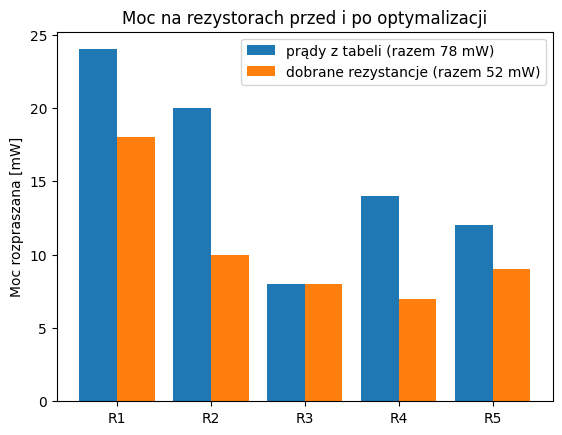

In [11]:
nazwy = [f"R{k}" for k in U]
moc_nom = [U[k] * I_nom[k] for k in U]
moc_opt = [U[k] * prady[k] for k in U]
x = range(len(nazwy))

plt.bar([i - 0.2 for i in x], moc_nom, width=0.4, label=f"prądy z tabeli (razem {sum(moc_nom):.0f} mW)")
plt.bar([i + 0.2 for i in x], moc_opt, width=0.4, label=f"dobrane rezystancje (razem {sum(moc_opt):.0f} mW)")
plt.xticks(list(x), nazwy)
plt.ylabel("Moc rozpraszana [mW]")
plt.title("Moc na rezystorach przed i po optymalizacji")
plt.legend()
plt.show()

Rys. 2Moc rozpraszana na każdym rezystorze dla prądów z tabeli i po dobraniu rezystancji

## 3. Sprawdzenie i interpretacja

Jest też prostszy sposób spojrzenia na to zadanie. Napięcie na całym mostku jest stałe (13 V z A do B), więc moc całego układu to $P = 13\ \text{V} \cdot I_{całk}$. **Minimalizacja mocy oznacza więc minimalizację prądu pobieranego przez mostek.**

- Prąd całkowity dla wartości z tabeli: $I_1 + I_2 = 4 + 2 = 6$ mA, czyli $P = 13 \cdot 6 = 78$ mW.
- Prąd całkowity po optymalizacji: $I_1 + I_2 = 3 + 1 = 4$ mA, czyli $P = 13 \cdot 4 = 52$ mW, tyle samo co z solvera.
- Mniej niż 4 mA się nie da. Prąd całkowity to też $I_4 + I_5$, a ich dolne granice to $1 + 3 = 4$ mA.

Sprawdzenie bilansu w węzłach: C: $I_1 = 3 = I_3 + I_4 = 2 + 1$ ✔, D: $I_2 + I_3 = 1 + 2 = 3 = I_5$ ✔.

## 4. Co jeśli zmieni się tolerancja?

Sprawdzamy, jak wynik zależy od tolerancji $\Delta$: mniejsza tolerancja to mniej swobody w doborze rezystancji.

Δ = 0 mA: P_min = 78.0 mW
Δ = 0.25 mA: P_min = 71.5 mW
Δ = 0.5 mA: P_min = 65.0 mW
Δ = 0.75 mA: P_min = 58.5 mW
Δ = 1.0 mA: P_min = 52.0 mW


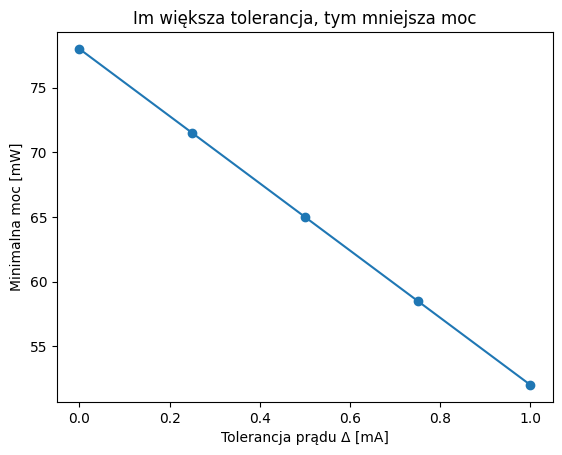

In [12]:
tolerancje = [0, 0.25, 0.5, 0.75, 1.0]
moce = []
for d in tolerancje:
    status, P, _ = rozwiaz(U, I_nom, {k: d for k in U})
    moce.append(P)
    print(f"Δ = {d} mA: P_min = {P:.1f} mW")

plt.plot(tolerancje, moce, "o-")
plt.xlabel("Tolerancja prądu Δ [mA]")
plt.ylabel("Minimalna moc [mW]")
plt.title("Im większa tolerancja, tym mniejsza moc")
plt.show()

Rys. 3. Minimalna moc w zależności od tolerancji prądów. Przy $\Delta = 0$ rezystancje są wyznaczone jednoznacznie (78 mW), a każde 0,25 mA tolerancji obniża moc o 6,5 mW.


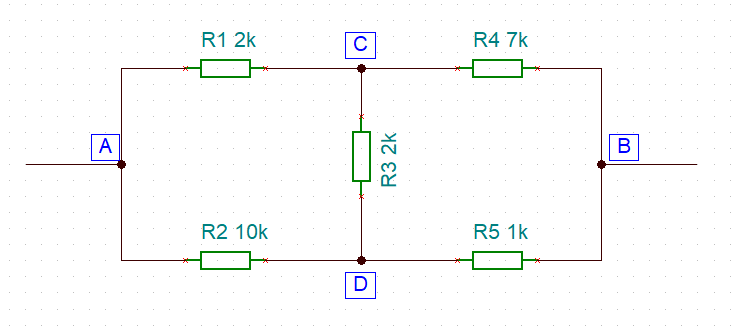


## Wnioski

- Bezpośrednio względem rezystancji zadanie jest nieliniowe, bo $P = U^2/R$. Wystarczy jednak przyjąć za zmienne decyzyjne **prądy**: przy stałych napięciach moc jest wtedy liniowa, a rezystancje liczymy na końcu z prawa Ohma.
- Minimalna moc rozpraszana na mostku to 52 mW (33% mniej niż dla wartości z tabeli). Dobrane rezystancje to R1 = 2 kΩ, R2 = 10 kΩ, R3 = 2 kΩ, R4 = 7 kΩ, R5 = 1 kΩ.
- Przy stałym napięciu mostka minimalizacja mocy to po prostu minimalizacja prądu całkowitego. Solver zszedł z prądami czterech rezystorów do dolnych granic, a R3 ustawił tak, żeby bilans w węzłach się zgadzał.
- Wynik zależy od tolerancji. Im większe $\Delta$, tym większa swoboda doboru rezystancji i mniejsza moc.